# MATPLOTLIB MASTERY — NOTEBOOK 4
## Chapters 26–35: Fill Between (Advanced) → Error Bars → Multiple Subplots → Layout Management → Figure Size/DPI → Saving Figures → Text Annotations → Annotating Data Points → Coordinate Systems → Twin Axes

Continuing directly from Notebook 3 (which already covered the *basics* of `fill_between` as part of Chapter 25). Chapter 26 below extends it with the advanced options; everything else is new ground.

### Progress Tracker (this notebook)
- [x] Chapter 26 — Fill Between (advanced: `where`, `interpolate`, `stackplot`)
- [x] Chapter 27 — Error Bars
- [x] Chapter 28 — Multiple Subplots
- [x] Chapter 29 — Subplot Layout
- [x] Chapter 30 — Figure Size and DPI
- [x] Chapter 31 — Saving Figures
- [x] Chapter 32 — Text Annotations
- [x] Chapter 33 — Annotating Data Points
- [x] Chapter 34 — Axes Coordinates vs Data Coordinates
- [x] Chapter 35 — Twin Axes


In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
np.random.seed(42)


---
# CHAPTER 26 — FILL BETWEEN (ADVANCED)

## 1. Concept (extending Chapter 25)
Two features turn `fill_between` from "shade a band" into a precise analytical tool: the `where=` mask (shade only where a condition holds) and `stackplot` (many `fill_between`-style layers stacked automatically — the area-chart analogue of Chapter 18's stacked bars).

## 2. Why It Matters
`where=` is the standard way to visually flag **regions of interest** — e.g., where actual performance dropped below a target threshold, or where a forecast exceeds a safety limit — without needing separate annotation for every occurrence.


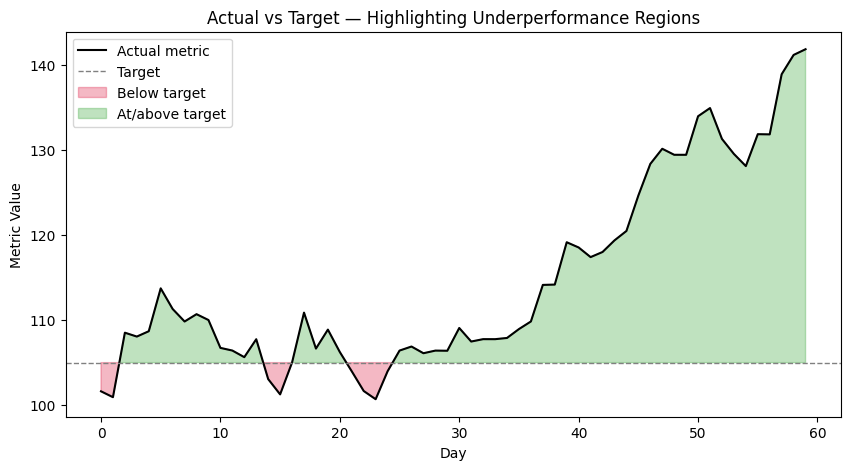

In [2]:
days = np.arange(60)
np.random.seed(5)
actual = 100 + np.cumsum(np.random.normal(0.3, 3, size=60))
target = 105

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(days, actual, color="black", linewidth=1.5, label="Actual metric")
ax.axhline(target, color="gray", linestyle="--", linewidth=1, label="Target")

# Shade ONLY where actual falls below target — the region of concern
ax.fill_between(
    days, actual, target,
    where=(actual < target),
    interpolate=True,          # correctly fills exactly at the crossing points, not just at sampled x's
    color="crimson", alpha=0.3, label="Below target",
)
ax.fill_between(
    days, actual, target,
    where=(actual >= target),
    interpolate=True,
    color="tab:green", alpha=0.3, label="At/above target",
)

ax.set_title("Actual vs Target — Highlighting Underperformance Regions")
ax.set_xlabel("Day")
ax.set_ylabel("Metric Value")
ax.legend()
plt.show()


### Parameter Explanation
- `where=(actual < target)` — a boolean NumPy array (same length as `x`) telling `fill_between` exactly which x-regions to shade.
- `interpolate=True` — **critical** when `where` is based on two crossing curves: without it, the fill stops abruptly at the last *sampled* point before a crossing, leaving a visible gap/triangle right at the crossing; with it, Matplotlib computes the true interpolated crossing point and fills right up to it.

### Common Mistakes
- Omitting `interpolate=True` with a `where=` mask on crossing curves — produces small but noticeable rendering gaps exactly at each crossing, which look like rendering bugs rather than the analytical artifact they are.
- Using `where=` without first plotting the actual/target lines themselves — the shading alone, with no reference lines, forces the reader to guess what threshold triggered the highlighting.

### `stackplot` — Automatic Stacked Area Charts
For cumulative, part-to-whole *time series* (the area-chart analogue of Chapter 18's stacked bars), `ax.stackplot()` handles the cumulative-sum bookkeeping automatically — you don't need to manually compute `bottom` arrays like you did for stacked bars.


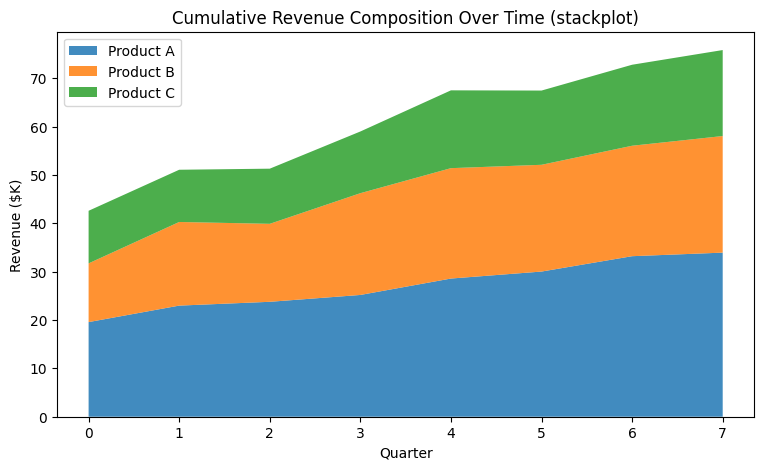

In [3]:
quarters_x = np.arange(8)
product_a_ts = 20 + quarters_x * 2 + np.random.normal(0, 1, 8)
product_b_ts = 15 + quarters_x * 1.5 + np.random.normal(0, 1, 8)
product_c_ts = 10 + quarters_x * 1.0 + np.random.normal(0, 1, 8)

fig, ax = plt.subplots(figsize=(9, 5))
ax.stackplot(
    quarters_x, product_a_ts, product_b_ts, product_c_ts,
    labels=["Product A", "Product B", "Product C"],
    alpha=0.85,
)
ax.set_title("Cumulative Revenue Composition Over Time (stackplot)")
ax.set_xlabel("Quarter")
ax.set_ylabel("Revenue ($K)")
ax.legend(loc="upper left")
plt.show()


### Internal Working
`ax.stackplot()` is a convenience wrapper that internally computes the same running cumulative sums you built manually in Chapter 18 for stacked bars, then issues one `fill_between`-style call per layer — it exists purely to save you from repeating that bookkeeping for area charts specifically.

### Best Practices
- Prefer `where=` + `interpolate=True` over manually splitting your data into separate above/below arrays — it's less error-prone and handles crossings correctly by construction.
- Use `stackplot` (not manual `fill_between` stacking) whenever you have a genuine multi-layer cumulative time series — less code, fewer bugs.

### Interview Insight
**Q: You need to shade the region where a metric line drops below a threshold, and the crossing happens between sampled points. What do you need to set to avoid a rendering artifact?**
A: `interpolate=True` on `fill_between`, alongside the boolean `where=` mask — this makes Matplotlib compute the true interpolated crossing point rather than stopping the fill at the last sampled x before the crossing.

### Mini Exercise
Change the `target` value to `95` and observe how the red/green shaded regions redistribute — confirm the shading logic still correctly follows the new threshold with no code changes beyond the constant.

### Quiz (Chapter 26)
1. What does `interpolate=True` fix specifically, and when is it needed?
2. What manual bookkeeping does `stackplot` save you from repeating?
3. Why should reference lines (`axhline`) usually accompany a `where=`-based fill?


---
# CHAPTER 27 — ERROR BARS

## 1. Concept
`ax.errorbar(x, y, yerr=..., xerr=...)` draws a marker/line at each `(x, y)` plus a vertical (and/or horizontal) bar showing the uncertainty around that point — the point-plot analogue of `fill_between`'s continuous band.

## 2. Why It Matters
Whenever you report an aggregated value (a mean, an experiment result), reporting it **without** its uncertainty is incomplete and can overstate confidence — a classic scientific-reporting and ML-experimentation requirement.

## 3–4. NumPy / Pandas Connection
`yerr` is typically `df.groupby("group")["value"].std()` or `.sem()` (standard error of the mean) — direct output of a Pandas aggregation, fed straight into `errorbar`.

## 5. Industry Use Case
A/B test results (mean conversion rate ± confidence interval per variant), experiment results across repeated runs, scientific measurement uncertainty.


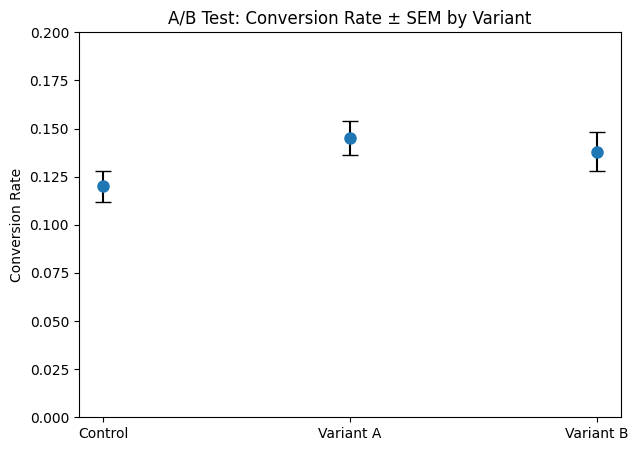

In [4]:
variants = ["Control", "Variant A", "Variant B"]
conversion_mean = np.array([0.12, 0.145, 0.138])
conversion_sem = np.array([0.008, 0.009, 0.010])   # standard error of the mean, per variant

fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(
    variants, conversion_mean, yerr=conversion_sem,
    fmt="o",              # marker style for the point itself
    capsize=6,             # small horizontal caps at each error bar end
    color="tab:blue",
    ecolor="black",        # error bar line color
    elinewidth=1.5,
    markersize=8,
)
ax.set_title("A/B Test: Conversion Rate ± SEM by Variant")
ax.set_ylabel("Conversion Rate")
ax.set_ylim(0, 0.2)
plt.show()


### Parameter Explanation
| Parameter | Meaning |
|---|---|
| `yerr` / `xerr` | Uncertainty magnitude — a scalar (same for all points), a 1D array (per-point, symmetric), or a `(2, N)` array for asymmetric lower/upper bounds |
| `fmt` | Marker/line style for the central point (`'o'` = circles only, no connecting line; `'o-'` = circles connected by a line) |
| `capsize` | Length of the small perpendicular caps at each error bar's end |
| `ecolor` | Color specifically for the error bar lines (can differ from the marker color) |
| `elinewidth` | Error bar line thickness |

### Internal Working
`ax.errorbar()` is a composite call: internally it creates a `Line2D`/marker collection for the central points **plus** a `LineCollection` for the error bar segments and caps — all bundled into one `ErrorbarContainer` return object.

### Interpretation
Variant A's mean conversion rate (14.5%) is higher than Control's (12%), but note the error bars: if Control's upper bound (≈12.8%) and Variant A's lower bound (≈13.6%) don't overlap, that's suggestive (though not a formal significance test) that the difference may be real rather than noise — exactly the visual instinct error bars are meant to support before running (or in addition to) a proper statistical test.

### Common Mistakes
- Reporting bar charts of means with **no error bars at all** — a serious omission in any experimental/scientific context, since it presents point estimates as if they were exact.
- Confusing standard deviation (spread of individual observations) with standard error of the mean (uncertainty of the *mean estimate itself*, which shrinks with more samples) — using the wrong one changes the entire interpretation of "how confident are we in this average."
- Assuming non-overlapping error bars are equivalent to statistical significance — they're a helpful visual heuristic, not a substitute for an actual hypothesis test (e.g., a t-test).

### Best Practices
- Always state, in the axis label or caption, exactly what the error bars represent (± SEM? ± 1 std dev? a 95% CI?) — these differ substantially and readers shouldn't have to guess.
- Combine error bars on a bar chart (`ax.bar(x, means, yerr=errs, capsize=5)`) when categories are also being compared by magnitude, not just point value.

### Interview Insight
**Q: What's the difference between using standard deviation vs standard error of the mean for error bars, and why does it matter?**
A: Standard deviation describes the spread of *individual* observations within a group and doesn't shrink with more data; standard error of the mean describes the uncertainty of the *estimated average itself* and shrinks as `1/sqrt(n)`. Using std when you mean to communicate confidence in the mean estimate overstates the visual uncertainty for large samples, and vice versa — so the choice must match the actual claim being made in the chart.

### Mini Exercise
Recreate the A/B test chart using standard deviation instead of SEM (assume std is roughly `sem * sqrt(n)` for `n=1000` per variant) and compare how much wider the bars become — illustrating why the choice matters.

### Quiz (Chapter 27)
1. What does `capsize` control?
2. Why must you always specify (in a label/caption) whether error bars represent SEM, std, or a CI?
3. Do non-overlapping error bars prove statistical significance?


---
# CHAPTER 28 — MULTIPLE SUBPLOTS

## 1. Concept
`fig, axes = plt.subplots(nrows=2, ncols=2)` creates a Figure containing a **grid** of Axes at once, returning `axes` as a 2D NumPy array of Axes objects (or 1D if one dimension is 1, or a bare Axes if both are 1 — a subtlety worth memorizing).

## 2. Why It Matters
This is the foundation of every **EDA dashboard**: instead of 4 separate `plt.show()` calls, you build one cohesive Figure showing 4 related views of the data side by side, which is how virtually every real-world exploratory analysis notebook actually looks.


/tmp/ipykernel_2492/4256370720.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 1].boxplot([df.loc[df["churned"] == 0, "tenure_months"],


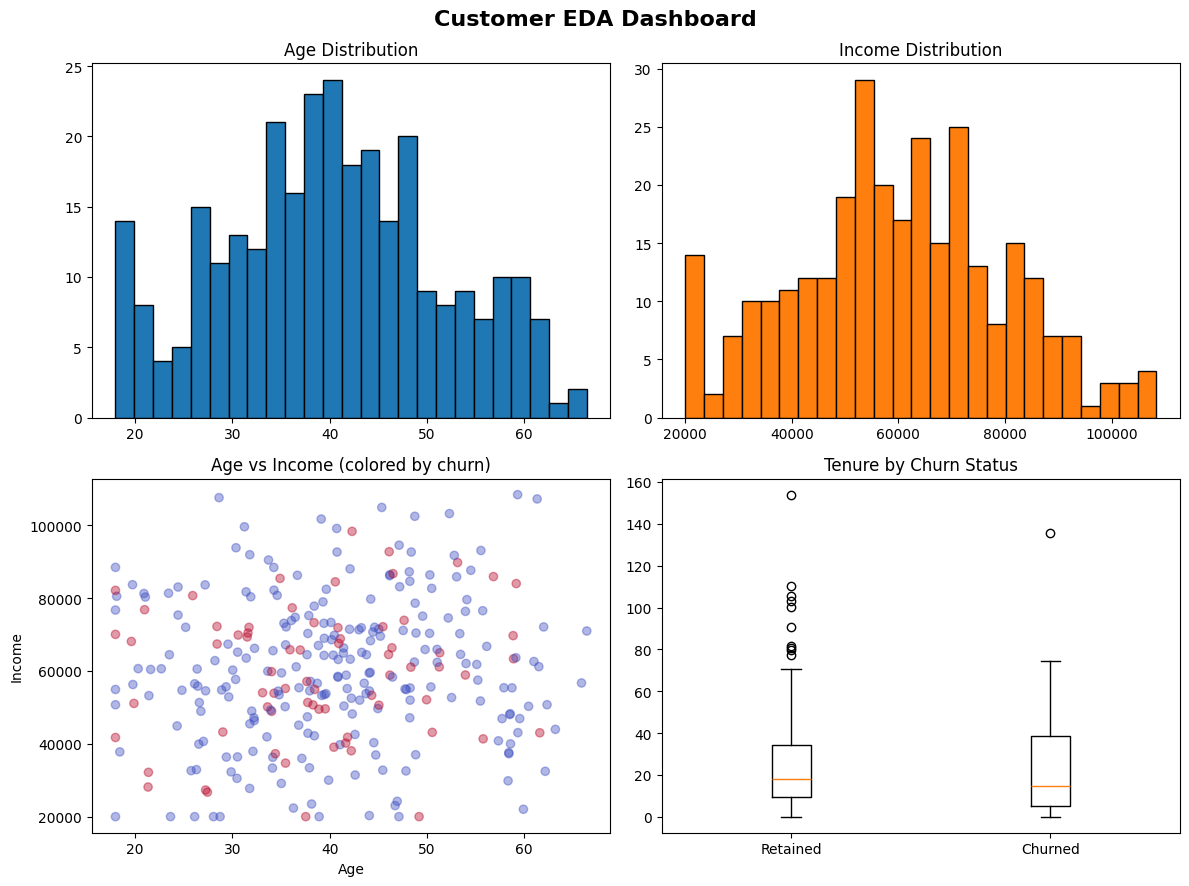

In [5]:
np.random.seed(11)
df = pd.DataFrame({
    "age": np.random.normal(40, 12, 300).clip(18, 75),
    "income": np.random.normal(60000, 20000, 300).clip(20000),
    "tenure_months": np.random.exponential(24, 300),
    "churned": np.random.choice([0, 1], size=300, p=[0.75, 0.25]),
})

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 9))

# axes is a 2D array here: index as axes[row, col]
axes[0, 0].hist(df["age"], bins=25, color="tab:blue", edgecolor="black")
axes[0, 0].set_title("Age Distribution")

axes[0, 1].hist(df["income"], bins=25, color="tab:orange", edgecolor="black")
axes[0, 1].set_title("Income Distribution")

axes[1, 0].scatter(df["age"], df["income"], alpha=0.4, c=df["churned"], cmap="coolwarm")
axes[1, 0].set_title("Age vs Income (colored by churn)")
axes[1, 0].set_xlabel("Age")
axes[1, 0].set_ylabel("Income")

axes[1, 1].boxplot([df.loc[df["churned"] == 0, "tenure_months"],
                     df.loc[df["churned"] == 1, "tenure_months"]],
                    labels=["Retained", "Churned"])
axes[1, 1].set_title("Tenure by Churn Status")

fig.suptitle("Customer EDA Dashboard", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()


### Line-by-Line / API Explanation
- `plt.subplots(nrows=2, ncols=2, figsize=(12, 9))` — one Figure, a 2×2 grid of 4 Axes.
- `axes[0, 0]`, `axes[0, 1]`, `axes[1, 0]`, `axes[1, 1]` — row-major indexing into the returned 2D array; **this is the #1 subplot indexing bug source** for beginners moving from a single-axes mental model.
- `fig.suptitle(...)` — a Figure-level title, distinct from each Axes' individual `set_title()` (Chapter 5) — used for an overall dashboard heading above all subplots.

### Flattening for Loop-Based Plotting
When the number of plots is data-driven (not a fixed 2×2), `axes.flatten()` (or `.ravel()`) turns the 2D grid into a simple 1D iterable — the standard pattern for looping over an arbitrary number of subplots:


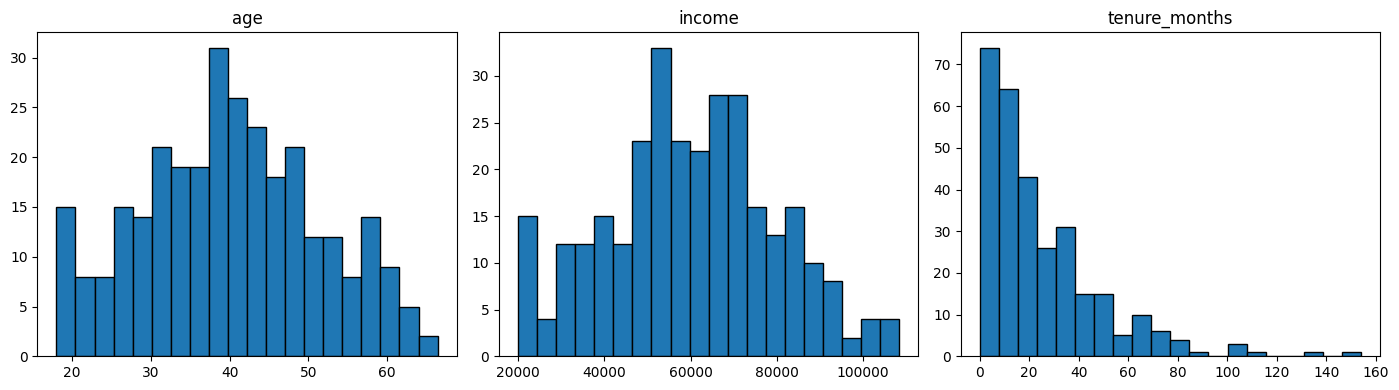

In [6]:
numeric_cols = ["age", "income", "tenure_months"]

fig, axes = plt.subplots(nrows=1, ncols=len(numeric_cols), figsize=(14, 4))
for ax, col in zip(axes.flatten(), numeric_cols):
    ax.hist(df[col], bins=20, color="tab:blue", edgecolor="black")
    ax.set_title(col)

plt.tight_layout()
plt.show()


### Internal Working
`plt.subplots(nrows, ncols)` internally calls `fig.add_gridspec(nrows, ncols)` to partition the Figure canvas into a grid, then calls `fig.add_subplot()` once per cell — each returned Axes knows its own position within that `GridSpec` (relevant again in more advanced, uneven-grid layouts beyond this course's scope).

### Common Mistakes
- Indexing `axes[0][0]` when `nrows=1` (or `ncols=1`) — in that case `plt.subplots()` returns a **1D** array, and `axes[0, 0]`/double-indexing raises an `IndexError`. Always check shape: 1×1 → bare Axes (no array), 1×N or N×1 → 1D array, N×M (both >1) → 2D array.
- Forgetting `plt.tight_layout()` (or `constrained_layout=True`, Chapter 29) with multiple subplots — titles/labels overlap between adjacent panels.
- Building a huge grid (4×4+) where each panel becomes too small to read — beyond ~6–9 panels, consider separate figures or an interactive alternative.

### Debugging
`IndexError: too many indices for array` on `axes[i, j]` → print `axes.shape` first; it tells you immediately whether you're dealing with a 1D or 2D array for this specific `nrows`/`ncols` combination.

### Best Practices
- Use `axes.flatten()` for loop-driven, data-count-dependent subplot grids rather than manually indexing each `[row, col]`.
- Always call `fig.suptitle()` for an overall dashboard heading, keeping per-panel `ax.set_title()` calls short and specific.

### Interview Insight
**Q: `plt.subplots(1, 3)` — what type/shape is the returned `axes`, and how do you iterate over it?**
A: A 1D NumPy array of length 3 (not 2D, since one dimension is 1) — iterate directly with `for ax in axes:` or index with `axes[i]`; `axes[i, j]` would raise an `IndexError` here since there's no second dimension.

### Mini Exercise
Build a `plt.subplots(3, 1)` grid, confirm `axes.shape == (3,)`, and populate each with a different histogram from `numeric_cols` using a `for` loop and `zip`.

### Quiz (Chapter 28)
1. What shape does `axes` have for `plt.subplots(2, 3)`? For `plt.subplots(1, 4)`? For `plt.subplots(1, 1)`?
2. What does `axes.flatten()` solve, and when is it necessary?
3. What's the difference between `fig.suptitle()` and `ax.set_title()`?


---
# CHAPTER 29 — SUBPLOT LAYOUT

## 1. Concept
Multi-panel figures frequently suffer from overlapping titles, clipped axis labels, and legends spilling outside the canvas. Matplotlib provides two main automatic fixes: `plt.tight_layout()` (a post-hoc adjustment) and `constrained_layout=True` (a live, continuously-applied layout engine set at Figure-creation time).

## 2. Why It Matters
An unpolished layout with overlapping text is one of the fastest ways for a chart to look unprofessional, regardless of how good the underlying analysis is.


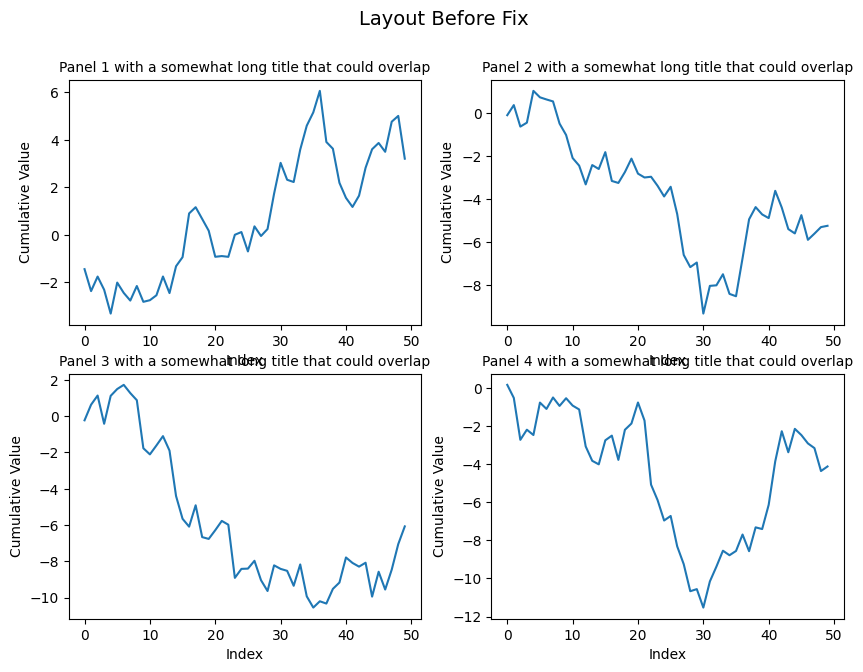

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for i, ax in enumerate(axes.flatten()):
    ax.plot(np.random.randn(50).cumsum())
    ax.set_title(f"Panel {i+1} with a somewhat long title that could overlap", fontsize=10)
    ax.set_xlabel("Index")
    ax.set_ylabel("Cumulative Value")

# WITHOUT tight_layout, titles/labels between panels commonly overlap.
# fig.suptitle ADDS another element that can collide with the top row's titles.
fig.suptitle("Layout Before Fix", fontsize=14)
plt.show()   # note: NOT calling tight_layout here, on purpose, to show the problem


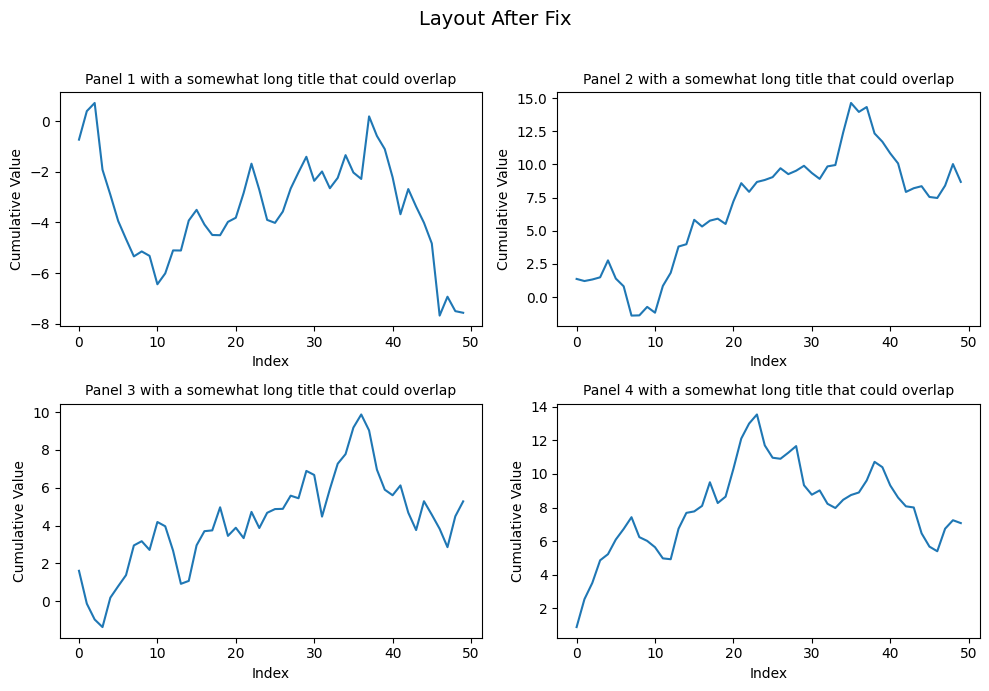

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for i, ax in enumerate(axes.flatten()):
    ax.plot(np.random.randn(50).cumsum())
    ax.set_title(f"Panel {i+1} with a somewhat long title that could overlap", fontsize=10)
    ax.set_xlabel("Index")
    ax.set_ylabel("Cumulative Value")

fig.suptitle("Layout After Fix", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])   # leave room at top for suptitle
plt.show()


### Parameter Explanation
- `plt.tight_layout()` — automatically adjusts subplot spacing (`wspace`, `hspace`) and margins to prevent overlaps, computed **once**, after all Artists exist.
- `rect=[left, bottom, right, top]` (fractions of the Figure, 0–1) — reserves space (here, the top 4%) so `fig.suptitle()` doesn't collide with the adjusted subplot titles.
- `constrained_layout=True` (passed to `plt.subplots(..., constrained_layout=True)`) — a newer, generally more robust alternative that recalculates layout continuously as you add legends/colorbars, rather than requiring one explicit post-hoc call.

### `constrained_layout` vs `tight_layout`


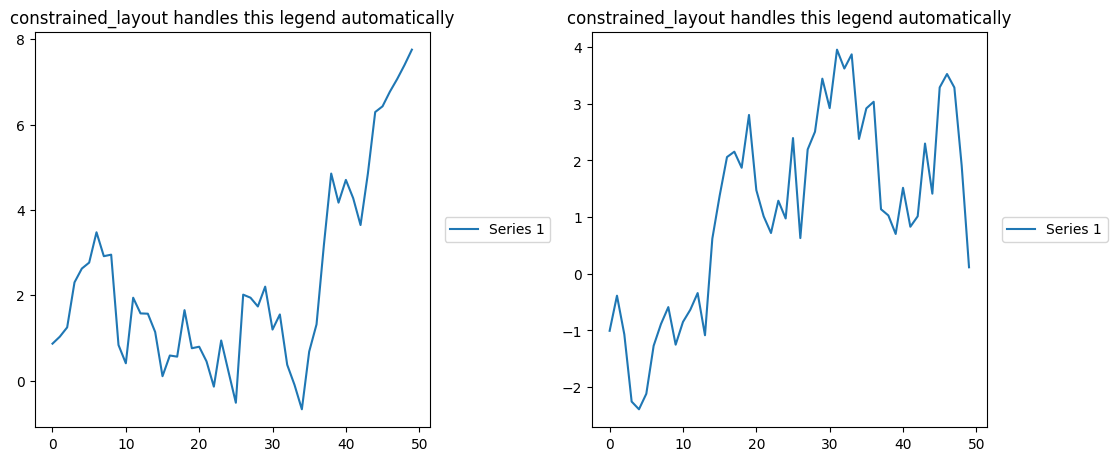

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for ax in axes:
    line, = ax.plot(np.random.randn(50).cumsum(), label="Series 1")
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))  # legend OUTSIDE the axes
    ax.set_title("constrained_layout handles this legend automatically")

plt.show()


### Internal Working
`tight_layout()` performs a single geometry solve based on the current renderer's measured text/Artist bounding boxes at call time — if you modify the figure afterward (e.g., add a colorbar), you may need to call it again. `constrained_layout` instead hooks into the draw pipeline and re-solves the layout on every draw, which is why it handles dynamically-added elements (like an externally-anchored legend) more gracefully without a second manual call.

### Common Mistakes
- Calling `tight_layout()` **before** adding a `fig.suptitle()` or an external legend — the layout solve won't know to reserve space for elements that don't exist yet; call it last, or switch to `constrained_layout=True`.
- Mixing `tight_layout()` and `constrained_layout=True` in the same figure — they can conflict; pick one strategy per figure.

### Best Practices
- For new code, prefer `constrained_layout=True` at `plt.subplots()` creation time as the default — it requires less manual intervention as a figure evolves.
- Reserve `tight_layout(rect=...)` for quick fixes on already-built figures or when working with older Matplotlib versions/codebases that don't use `constrained_layout`.

### Interview Insight
**Q: What's the practical difference between `tight_layout()` and `constrained_layout=True`?**
A: `tight_layout()` is a one-time, post-hoc geometry adjustment you call explicitly (often needing to be re-called if the figure changes afterward); `constrained_layout=True` is set at Figure-creation time and continuously re-solves layout on every draw, handling dynamically added elements like externally-placed legends or colorbars more robustly without additional manual calls.

### Mini Exercise
Take the "Layout Before Fix" example and add `constrained_layout=True` to the `plt.subplots()` call instead of calling `tight_layout()` afterward — compare the result.

### Quiz (Chapter 29)
1. What problem does `tight_layout()`/`constrained_layout` solve?
2. Why might you need to re-call `tight_layout()` after adding a new Artist, but not with `constrained_layout=True`?
3. What does the `rect=` parameter of `tight_layout()` control?


---
# CHAPTER 30 — FIGURE SIZE AND DPI

## 1. Concept
- `figsize=(width, height)` — the Figure's physical dimensions in **inches**.
- `dpi` (dots per inch) — the pixel density; final raster pixel dimensions = `figsize × dpi`.

A `figsize=(8, 5)` figure at `dpi=100` renders as an 800×500 pixel image; the same figure at `dpi=300` renders as 2400×1500 pixels — same physical layout and proportions, far higher resolution.

## 2. Why It Matters
- **Notebook/screen viewing**: default `dpi` (~72–100) is fine — file size and render speed matter more than ultra-high resolution.
- **Presentations**: slightly larger `figsize`, moderate `dpi` (~150).
- **Print/publication**: `dpi=300`+ is close to a universal minimum standard for print-quality raster graphics.


Figure size in inches: [6. 4.]
Rendered pixel dimensions (approx): [600. 400.]


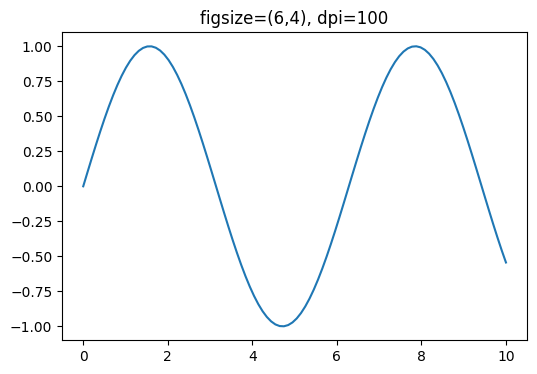

In [10]:
fig, ax = plt.subplots(figsize=(6, 4), dpi=100)
ax.plot(np.linspace(0, 10, 100), np.sin(np.linspace(0, 10, 100)))
ax.set_title("figsize=(6,4), dpi=100")

print("Figure size in inches:", fig.get_size_inches())
print("Rendered pixel dimensions (approx):", fig.get_size_inches() * fig.dpi)
plt.show()


### Parameter Explanation
- `fig.get_size_inches()` — returns `[width, height]` in inches, independent of `dpi`.
- `fig.dpi` — the currently set dots-per-inch; `fig.set_dpi(300)` changes it after creation.
- Note: `figsize` controls the **layout proportions and relative sizing of text/lines** (a `figsize=(4,3)` plot's default 12pt title will look proportionally larger than the same title on a `figsize=(12,9)` plot) — `dpi` alone controls sharpness/pixel count, not layout.

### Common Mistakes
- Increasing only `dpi` to "make a plot bigger" — this increases resolution/sharpness, not the physical/relative size of text and elements; to make text/lines relatively bigger, increase `figsize` (or decrease it to make everything relatively smaller within the same pixel count).
- Using a tiny `figsize` (e.g., `(3, 2)`) with many subplots — default font sizes become disproportionately large relative to the plot area, causing overlap; scale `figsize` with subplot grid size.
- Exporting screen-resolution (`dpi=72`) figures for a printed report — comes out visibly blurry/pixelated.

### Best Practices
- Screen/notebook exploration: default dpi is fine.
- Any deliverable meant for printing, a PDF report, or a poster: `dpi=300` minimum.
- Scale `figsize` up as you add more subplots to a grid, to keep per-panel proportions reasonable (e.g., `figsize=(4*ncols, 3*nrows)` is a common rule-of-thumb starting point).

### Interview Insight
**Q: You increase `dpi` from 100 to 300 but the chart's text and lines still look the same relative size on screen — what happened, and is that expected?**
A: Yes — `dpi` increases pixel density/sharpness, not the physical layout proportions; `figsize` (in inches) governs the relative size of text, line widths, and spacing. To make elements relatively larger or smaller within the frame, `figsize` (or explicit font-size parameters) needs to change, not `dpi` alone.

### Mini Exercise
Create the same plot at `figsize=(3, 2)` and `figsize=(12, 8)`, both at the same `dpi=100`, and compare how proportionally large the default-sized title text appears in each.

### Quiz (Chapter 30)
1. What two settings together determine a saved figure's final pixel dimensions?
2. What's the practical difference between increasing `dpi` vs increasing `figsize`?
3. What `dpi` is the common minimum standard for print/publication?


---
# CHAPTER 31 — SAVING FIGURES

## 1. Concept
`fig.savefig(path, **kwargs)` writes the current Figure to disk in a format inferred from the file extension.

## 2. Why It Matters
This is the actual delivery mechanism for portfolio work, reports, and any figure that needs to leave the notebook — getting format/resolution/cropping right the first time avoids a frustrating "the image looks cut off / blurry / has a weird background" cycle.

## Format Guide
| Format | Best for | Notes |
|---|---|---|
| PNG | Web, presentations, notebooks | Raster, lossless, supports transparency |
| JPG | Photographs (rarely ideal for charts) | Lossy compression — can introduce artifacts around sharp text/lines; avoid for charts with text |
| SVG | Web (scalable), further editing (Illustrator/Inkscape) | Vector — infinitely scalable, no pixelation, larger file for very complex/dense plots |
| PDF | Print, academic papers, LaTeX documents | Vector — the standard for publication-quality print output |


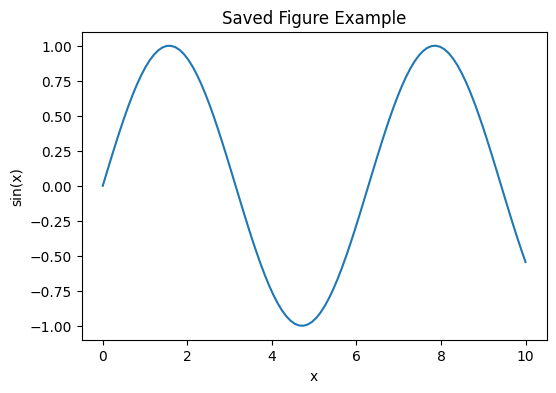

Saved files: ['sine_wave.png', 'sine_wave.pdf', 'sine_wave.svg']


In [11]:
import os
os.makedirs("/home/claude/figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.linspace(0, 10, 100), np.sin(np.linspace(0, 10, 100)), color="tab:blue")
ax.set_title("Saved Figure Example")
ax.set_xlabel("x")
ax.set_ylabel("sin(x)")

fig.savefig(
    "/home/claude/figures/sine_wave.png",
    dpi=300,
    bbox_inches="tight",   # crop excess whitespace around the figure
    transparent=False,
    facecolor="white",
)
fig.savefig("/home/claude/figures/sine_wave.svg", bbox_inches="tight")
fig.savefig("/home/claude/figures/sine_wave.pdf", bbox_inches="tight")

plt.show()
print("Saved files:", os.listdir("/home/claude/figures"))


### Parameter Explanation
| Parameter | Meaning |
|---|---|
| `dpi` | Resolution for raster formats (PNG/JPG) — ignored for vector formats (SVG/PDF), which are resolution-independent by nature |
| `bbox_inches="tight"` | Crops the saved image to the actual content bounds, removing excess whitespace — almost always what you want |
| `transparent` | If `True`, the background becomes transparent (useful for overlaying on slides with a non-white background) |
| `facecolor` | Explicit background color (overridden to transparent if `transparent=True`) |
| `format` | Explicit format override, if you want a non-standard file extension to still save as e.g. PNG |

### Common Mistakes
- Forgetting `bbox_inches="tight"` — saved figures often have noticeably more whitespace margin than what's shown inline in the notebook.
- Saving as JPG for a chart with fine text/thin lines — JPEG's lossy compression introduces visible artifacts ("ringing") around sharp edges, which text and axis lines are full of; PNG is almost always the better raster choice for charts.
- Calling `fig.savefig()` **after** `plt.show()` in a script — in some backends, `plt.show()` can clear/close the figure, resulting in a blank saved file. Save before showing, or keep a reference to `fig` and confirm it's still open.

### Best Practices
- PNG for anything going into a slide deck, doc, or web page; SVG/PDF for anything that needs to scale (posters) or be further edited/embedded in a LaTeX report.
- Always pass `bbox_inches="tight"`.
- Save at `dpi=300` as a default professional minimum for any raster export.

### Interview Insight
**Q: You need a figure that will be resized in a LaTeX paper without ever looking blurry. What format do you save it as, and why?**
A: PDF (or SVG) — vector formats store the actual drawing instructions (paths, text) rather than a fixed pixel grid, so they render crisply at any scale, unlike PNG/JPG, which are inherently resolution-limited by their `dpi` at save time.

### Mini Exercise
Save the same figure as both PNG and JPG at `dpi=150`, open both, and zoom in closely on the axis text to spot the JPEG compression artifacts around the letters.

### Quiz (Chapter 31)
1. Why is `dpi` irrelevant for SVG/PDF exports?
2. What does `bbox_inches="tight"` fix?
3. Why is PNG generally preferred over JPG for charts specifically?


---
# CHAPTER 32 — TEXT ANNOTATIONS

## 1. Concept
- `ax.text(x, y, "string")` places plain text at a data coordinate.
- `ax.annotate("string", xy=(x, y), xytext=(x2, y2), arrowprops=...)` places text **plus an arrow** pointing from the text back to a specific data point — the standard tool for calling out a specific feature of a chart.

## 2. Why It Matters
A well-placed annotation turns a chart from "here's the data, you figure out the story" into "here's the data, and here's specifically what matters" — essential for stakeholder-facing reports where you can't stand next to every reader to narrate.


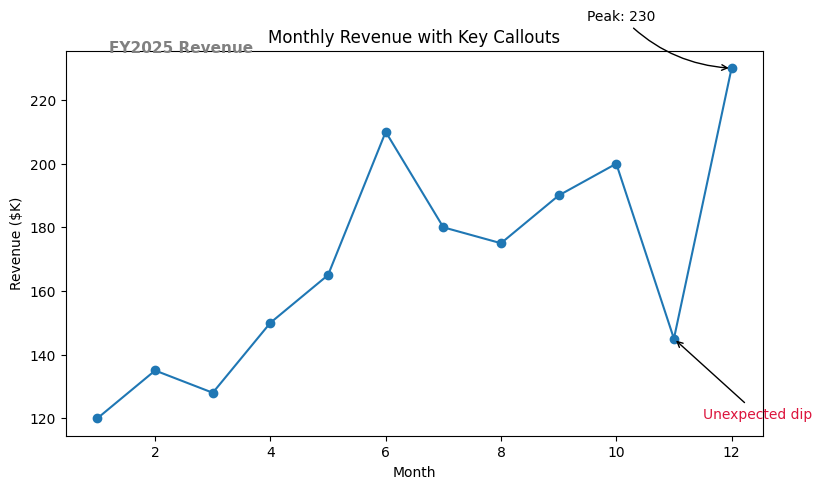

In [12]:
x_line = np.arange(1, 13)
revenue_line = np.array([120, 135, 128, 150, 165, 210, 180, 175, 190, 200, 145, 230])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x_line, revenue_line, marker="o", color="tab:blue")

# Plain text label
ax.text(1.2, 235, "FY2025 Revenue", fontsize=11, fontweight="bold", color="gray")

# Annotate the peak with an arrow
peak_idx = np.argmax(revenue_line)
ax.annotate(
    f"Peak: {revenue_line[peak_idx]}",
    xy=(x_line[peak_idx], revenue_line[peak_idx]),      # the point being pointed at
    xytext=(x_line[peak_idx] - 2.5, revenue_line[peak_idx] + 15),  # where the text sits
    arrowprops=dict(facecolor="black", arrowstyle="->", connectionstyle="arc3,rad=0.2"),
    fontsize=10,
)

# Annotate a notable dip
dip_idx = np.argmin(revenue_line[6:]) + 6   # dip in the second half
ax.annotate(
    "Unexpected dip",
    xy=(x_line[dip_idx], revenue_line[dip_idx]),
    xytext=(x_line[dip_idx] + 0.5, revenue_line[dip_idx] - 25),
    arrowprops=dict(facecolor="crimson", arrowstyle="->"),
    fontsize=10, color="crimson",
)

ax.set_title("Monthly Revenue with Key Callouts")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue ($K)")
plt.show()


### Parameter Explanation
| Parameter | Meaning |
|---|---|
| `xy` | The data point the annotation refers to (where the arrow points) |
| `xytext` | Where the text itself is placed (can differ from `xy` to avoid overlapping the data) |
| `arrowprops` | Dict controlling the arrow: `facecolor`/`edgecolor`, `arrowstyle` (`'->'`, `'-|>'`, `'fancy'`, etc.), `connectionstyle` (`'arc3,rad=0.2'` for a curved arrow, useful to route around other chart elements) |
| `fontsize`, `color`, `fontweight` | Standard text styling, identical to titles/labels |
| `ha`, `va` | Horizontal/vertical alignment of the text relative to its anchor point |

### Internal Working
Both `ax.text()` and `ax.annotate()` create `Text` Artists (annotate wraps an `Annotation`, a `Text` subclass that also manages an optional `FancyArrowPatch`). By default, `xy`/`xytext` coordinates are interpreted in **data coordinates** (Chapter 34 covers the alternative coordinate systems this can use).

### Common Mistakes
- Placing `xytext` directly on top of `xy` (no offset) — defeats the purpose of using `annotate` over plain `text`, since the label then overlaps the exact point it describes.
- Over-annotating — labeling every single point on a chart clutters it as badly as no labels at all; reserve annotations for the 1–3 points that are genuinely the message of the chart.
- Forgetting `arrowprops` entirely when using `annotate()` with a distant `xytext` — without it, there's no visual line connecting the text back to its data point, and the reader has to guess what it refers to.

### Best Practices
- Limit annotations to the specific points that are the actual analytical takeaway — not a caption for every data point.
- Use consistent arrow/text styling across a report so annotations read as a deliberate, single visual language rather than ad-hoc afterthoughts.

### Interview Insight
**Q: What's the difference between `ax.text()` and `ax.annotate()`, and when would you choose each?**
A: `ax.text()` places a string at a coordinate with no connecting arrow — good for general captions or labels not tied to one specific point. `ax.annotate()` is built specifically to point an arrow from explanatory text back to a precise data point — the right choice whenever you're calling out a specific peak, dip, or outlier and want the visual link to be unambiguous.

### Mini Exercise
Add a third annotation pointing out the first data point (January) using `ax.annotate()` with a straight (non-curved) arrow — omit `connectionstyle` and compare the arrow shape to the curved one used for the peak.

### Quiz (Chapter 32)
1. What's the key structural difference between `ax.text()` and `ax.annotate()`?
2. What does `connectionstyle="arc3,rad=0.2"` control?
3. Why is over-annotating a chart just as harmful as under-labeling it?


---
# CHAPTER 33 — ANNOTATING DATA POINTS (PROGRAMMATICALLY)

## 1. Concept
Chapter 32 hand-picked which points to annotate. In production/EDA code, you almost always want to **compute** which points matter (biggest error, highest/lowest value) using NumPy/Pandas indexing, then annotate those programmatically — so the code stays correct as the underlying data changes.

## 2. Why It Matters
Hardcoded annotation coordinates break the moment the dataset updates (next month's data, a re-run pipeline). Deriving the annotated point directly from the data via `np.argmax`/`idxmax` keeps the chart-generation code correct and reusable.


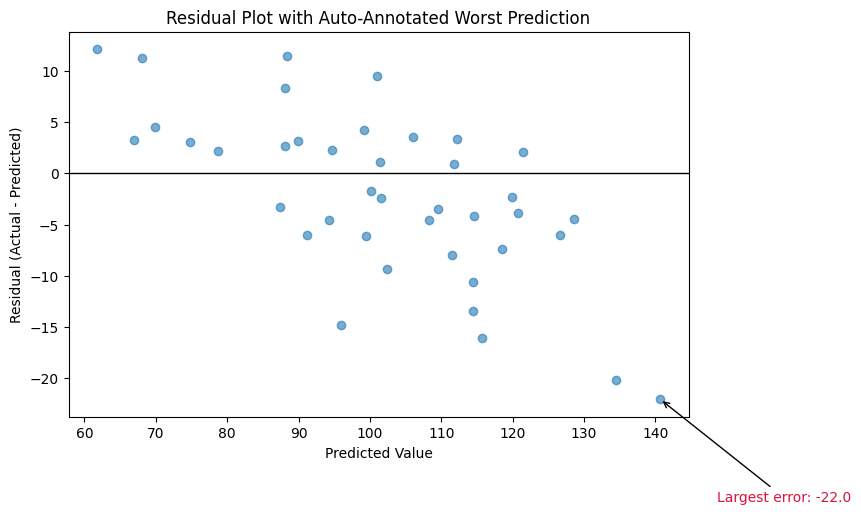

In [13]:
np.random.seed(21)
y_actual = np.random.normal(100, 15, 40)
y_pred = y_actual + np.random.normal(0, 8, 40)
residuals = y_actual - y_pred

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(y_pred, residuals, alpha=0.6, color="tab:blue")
ax.axhline(0, color="black", linewidth=1)

# Programmatically find and annotate the single LARGEST absolute error
worst_idx = np.argmax(np.abs(residuals))
ax.annotate(
    f"Largest error: {residuals[worst_idx]:.1f}",
    xy=(y_pred[worst_idx], residuals[worst_idx]),
    xytext=(y_pred[worst_idx] + 8, residuals[worst_idx] + (10 if residuals[worst_idx] > 0 else -10)),
    arrowprops=dict(facecolor="crimson", arrowstyle="->"),
    color="crimson", fontsize=10,
)

ax.set_title("Residual Plot with Auto-Annotated Worst Prediction")
ax.set_xlabel("Predicted Value")
ax.set_ylabel("Residual (Actual - Predicted)")
plt.show()


### Line-by-Line Explanation
- `np.argmax(np.abs(residuals))` — the standard NumPy idiom for "index of the largest-magnitude value," used here to find the model's single worst prediction regardless of whether it over- or under-predicted.
- The conditional offset `(10 if residuals[worst_idx] > 0 else -10)` — a small but important robustness detail: it places the annotation text *above* the point if the residual is positive and *below* if negative, so the label never overlaps the reference line at `y=0` regardless of which direction the worst error happened to be in.

### Generalizing to Top-N Annotations


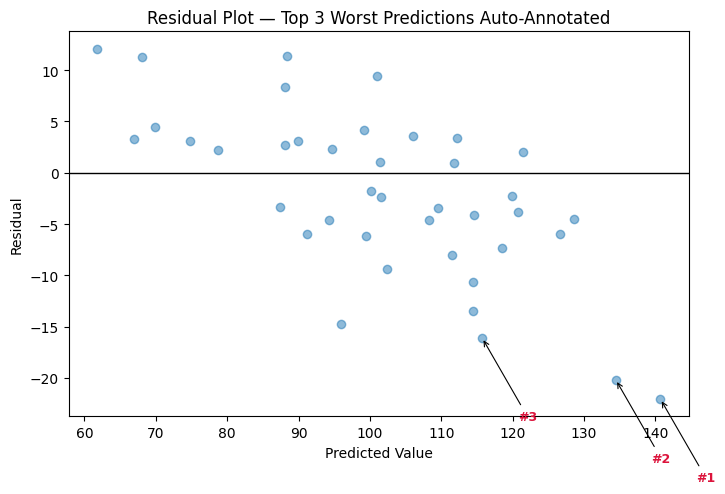

In [14]:
top_n = 3
worst_indices = np.argsort(np.abs(residuals))[::-1][:top_n]   # indices of the N largest-magnitude residuals

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(y_pred, residuals, alpha=0.5, color="tab:blue")
ax.axhline(0, color="black", linewidth=1)

for rank, idx in enumerate(worst_indices, start=1):
    ax.annotate(
        f"#{rank}",
        xy=(y_pred[idx], residuals[idx]),
        xytext=(y_pred[idx] + 5, residuals[idx] + (8 if residuals[idx] > 0 else -8)),
        arrowprops=dict(facecolor="crimson", arrowstyle="->", lw=0.8),
        color="crimson", fontsize=9, fontweight="bold",
    )

ax.set_title(f"Residual Plot — Top {top_n} Worst Predictions Auto-Annotated")
ax.set_xlabel("Predicted Value")
ax.set_ylabel("Residual")
plt.show()


### Internal Working
`np.argsort(np.abs(residuals))[::-1][:top_n]` — sorts indices by absolute residual ascending, reverses to descending, then slices the top N — a compact, reusable pattern for "give me the indices of the N most extreme values" that appears constantly in error-analysis code (Chapter 65).

### Common Mistakes
- Hardcoding annotation coordinates from a one-time visual inspection instead of deriving them via `argmax`/`argsort` — breaks silently (annotates the wrong, now-stale point) the next time the underlying data changes.
- Not handling the sign of the value when computing a text offset — leads to annotation text overlapping the very point/line it's meant to clarify, exactly the failure the conditional offset above avoids.

### Best Practices
- Always derive "interesting point" coordinates programmatically from the data (`argmax`, `argmin`, `nlargest`, `idxmax` for Pandas) rather than reading values off a rendered chart and typing them in.
- Encapsulate the top-N annotation loop into a reusable function when this pattern will be used across many model-evaluation charts (a natural fit for the `visualization.py` module built in Chapter 87).

### Interview Insight
**Q: Why is it considered bad practice to hardcode the coordinates of an annotated data point?**
A: Because the chart-generation code silently becomes wrong the moment the underlying data changes (new pipeline run, updated dataset) — the annotation will still appear at the old, now-arbitrary coordinates instead of tracking whatever the actual extreme point is. Deriving the point via `argmax`/`argsort` keeps the code correct and reusable indefinitely.

### Mini Exercise
Modify the top-N example to annotate the **best** (smallest absolute residual) prediction instead, using `np.argsort(np.abs(residuals))[:top_n]` (no reversal).

### Quiz (Chapter 33)
1. What NumPy function finds the single index of the largest-magnitude value in an array?
2. What's the risk of hardcoding an annotation's data coordinates?
3. Walk through what `np.argsort(np.abs(residuals))[::-1][:top_n]` computes, step by step.


---
# CHAPTER 34 — AXES COORDINATES VS DATA COORDINATES

## 1. Concept
Every Artist's position can be specified in one of several coordinate systems, controlled via the `transform=` parameter:
| System | Range | Meaning |
|---|---|---|
| **Data coordinates** (default) | Matches your actual data's scale | "Put this at x=50, y=200" — the default for `ax.plot()`, `ax.text()`, `ax.annotate()`'s `xy` |
| **Axes coordinates** | Always `(0, 0)` bottom-left to `(1, 1)` top-right of the Axes, regardless of data range | "Put this in the top-right corner of the plot, no matter what the data range is" |
| **Figure coordinates** | Always `(0, 0)` to `(1, 1)` across the *entire Figure*, spanning all subplots | "Put this in the exact center of the whole Figure" |

## 2. Why It Matters
Axes-coordinate placement is essential for elements that should stay in a **fixed relative position** regardless of the data's actual range — e.g., a "Source: Internal Analytics" watermark always in the bottom-right corner, no matter what values are plotted.


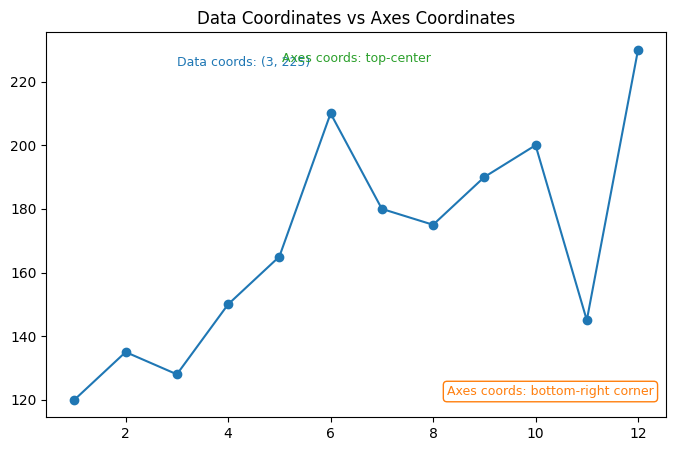

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x_line, revenue_line, marker="o")

# Data coordinates (default) — tied to the actual data scale
ax.text(3, 225, "Data coords: (3, 225)", color="tab:blue", fontsize=9)

# Axes coordinates — always relative to THIS Axes' box, regardless of data range
ax.text(0.98, 0.05, "Axes coords: bottom-right corner",
        transform=ax.transAxes, ha="right", va="bottom",
        fontsize=9, color="tab:orange",
        bbox=dict(facecolor="white", edgecolor="tab:orange", boxstyle="round"))

ax.text(0.5, 0.95, "Axes coords: top-center",
        transform=ax.transAxes, ha="center", va="top", fontsize=9, color="tab:green")

ax.set_title("Data Coordinates vs Axes Coordinates")
plt.show()


### Parameter Explanation
- `transform=ax.transAxes` — switches the interpretation of the `(x, y)` arguments from data units to the 0–1 Axes-relative fraction system.
- `transform=fig.transFigure` — the Figure-wide equivalent, used for elements meant to be positioned relative to the whole canvas (e.g., a single caption below a 2×2 subplot grid).
- `bbox=dict(...)` — draws a background box behind text, useful for ensuring a watermark/label stays legible regardless of what's plotted underneath it.

### Internal Working
Every Matplotlib coordinate ultimately passes through a `Transform` object before being converted to actual screen pixels; `ax.transData`, `ax.transAxes`, and `fig.transFigure` are three of the most commonly used pre-built `Transform` instances, each mapping its own coordinate space onto the final display pixels. This is genuinely how Matplotlib's rendering pipeline is architected internally (Chapter 83 revisits this from the "internals" angle).

### Interpretation / Practical Use Case
A "Confidential — Internal Use Only" or "Source: Company Analytics" watermark placed with `transform=ax.transAxes` at, say, `(0.99, 0.01)` will always land in the bottom-right corner of the plot **no matter how the underlying data's x/y ranges change** — critical for a report template that gets regenerated automatically with new data.

### Common Mistakes
- Forgetting `transform=ax.transAxes` and instead guessing a data-coordinate position for a "corner label" — breaks the moment the plotted data's range changes (e.g., next month's revenue exceeds the hardcoded y-value used for the label).
- Confusing Axes coordinates (relative to one subplot) with Figure coordinates (relative to the whole canvas) when working with multi-panel figures — a Figure-coordinate `(0.5, 0.5)` is the center of the *entire* Figure, not the center of any individual subplot.

### Best Practices
- Use `transform=ax.transAxes` for any fixed-position annotation (watermarks, "Panel A" labels, corner notes) that should stay put regardless of data range.
- Use `fig.transFigure` specifically for elements meant to span/relate to multiple subplots at once (e.g., one caption below a whole grid).

### Interview Insight
**Q: You want to place a "Source: ..." label in the exact same visual corner of a chart every time it's regenerated, regardless of what data range is plotted. How?**
A: Use `ax.text(x, y, "...", transform=ax.transAxes)` with `x, y` in the `[0, 1]` Axes-fraction range (e.g., `(0.99, 0.01)` for bottom-right) — this decouples the label's position from the data's actual scale entirely.

### Mini Exercise
Add a Figure-level caption ("Confidential") using `transform=fig.transFigure` at `(0.5, 0.01)` to a 1×2 subplot figure, and confirm it's centered under *both* panels combined, not just one.

### Quiz (Chapter 34)
1. What are the three main coordinate systems, and what range does each span?
2. Why is `ax.transAxes` the right choice for a watermark label?
3. What's the difference between Axes coordinates and Figure coordinates in a multi-panel figure?


---
# CHAPTER 35 — TWIN AXES

## 1. Concept
`ax2 = ax.twinx()` creates a second y-axis sharing the same x-axis as `ax`, letting you plot two series with **different units/scales** on one chart (e.g., revenue in dollars and conversion rate as a percentage, against the same time axis).

## 2. Why It Matters — and the Professional Warning
Dual-axis charts are one of the most **frequently misused** chart types: because the two y-axes have independent, often arbitrarily-chosen scales, you can make almost **any two unrelated series appear correlated** just by adjusting one axis's range — a well-documented manipulation technique. Use twin axes only when genuinely necessary, and always label each axis's color/units unambiguously.


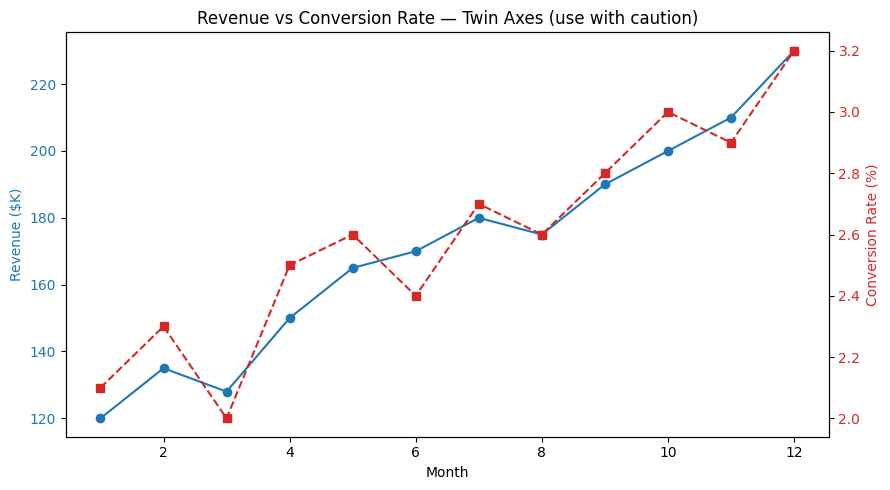

In [16]:
months_x = np.arange(1, 13)
revenue_twin = np.array([120, 135, 128, 150, 165, 170, 180, 175, 190, 200, 210, 230])
conversion_rate = np.array([2.1, 2.3, 2.0, 2.5, 2.6, 2.4, 2.7, 2.6, 2.8, 3.0, 2.9, 3.2])

fig, ax1 = plt.subplots(figsize=(9, 5))

color1 = "tab:blue"
ax1.plot(months_x, revenue_twin, color=color1, marker="o", label="Revenue ($K)")
ax1.set_xlabel("Month")
ax1.set_ylabel("Revenue ($K)", color=color1)
ax1.tick_params(axis="y", labelcolor=color1)

ax2 = ax1.twinx()   # shares the same x-axis; independent y-axis
color2 = "tab:red"
ax2.plot(months_x, conversion_rate, color=color2, marker="s", linestyle="--", label="Conversion Rate (%)")
ax2.set_ylabel("Conversion Rate (%)", color=color2)
ax2.tick_params(axis="y", labelcolor=color2)

ax1.set_title("Revenue vs Conversion Rate — Twin Axes (use with caution)")
fig.tight_layout()
plt.show()


### Line-by-Line Explanation
- `ax2 = ax1.twinx()` — creates a new Axes that **shares** `ax1`'s x-axis (same `xlim`, same tick positions) but has its **own independent** y-axis, limits, and scale.
- `color1`/`color2` applied consistently to the line **and** its corresponding axis label/ticks (`tick_params(labelcolor=...)`) — essential so the reader can tell which axis belongs to which series without a combined legend (combining legends across twin axes requires manually merging handles, an extra step often skipped, so color-coding the axes themselves is the more robust convention).

### Internal Working
`twinx()` creates a genuinely separate `Axes` object stacked in the same Figure position, with its `sharex` attribute pointing at the original — this is why the x-axis ticks/gridlines stay synchronized between the two while y-limits remain fully independent.

### The Manipulation Risk, Demonstrated


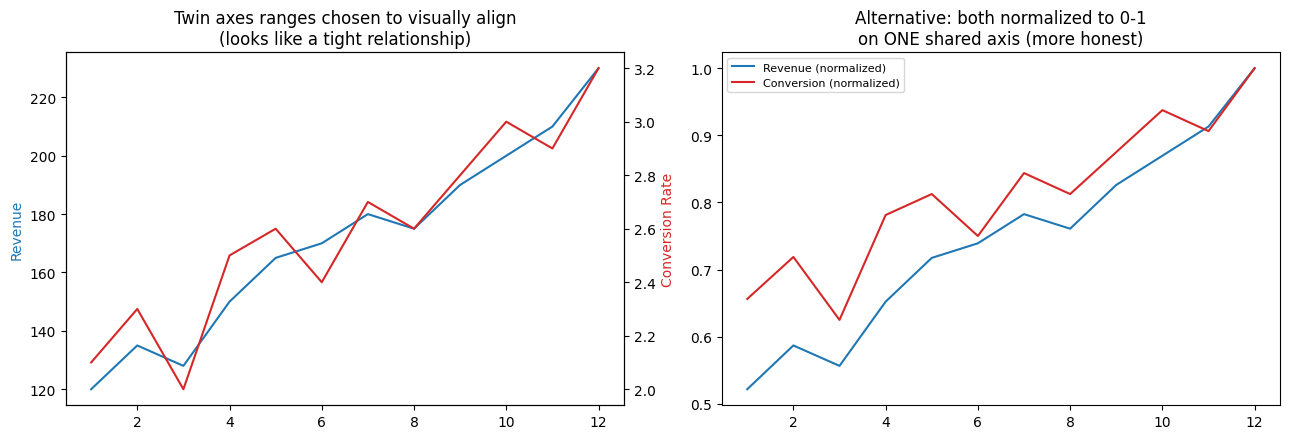

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel 1: seemingly correlated because y-axis RANGES were chosen to align visually
ax1 = axes[0]
ax1.plot(months_x, revenue_twin, color="tab:blue")
ax1.set_ylabel("Revenue", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(months_x, conversion_rate, color="tab:red")
ax2.set_ylabel("Conversion Rate", color="tab:red")
ax1.set_title("Twin axes ranges chosen to visually align\n(looks like a tight relationship)")

# Panel 2: same two series, plotted as separate small multiples instead
axes2 = axes[1]
axes2.plot(months_x, revenue_twin / revenue_twin.max(), color="tab:blue", label="Revenue (normalized)")
axes2.plot(months_x, conversion_rate / conversion_rate.max(), color="tab:red", label="Conversion (normalized)")
axes2.set_title("Alternative: both normalized to 0-1\non ONE shared axis (more honest)")
axes2.legend(fontsize=8)

plt.tight_layout()
plt.show()


### Interpretation
The left panel's dual-axis presentation can create a visual impression of tight correlation that is substantially an artifact of how the two independent y-axis ranges happen to have been scaled — a different (equally "valid") choice of ranges could make the two lines diverge visually instead. The right panel's normalized-to-a-shared-axis alternative removes that specific ambiguity, at the cost of losing the series' original units (a real trade-off, not a free win — it works well specifically when *relative trend* is what matters, less well when absolute values must be read directly off the chart).

### Common Mistakes
- Using twin axes purely because "the units are different," without considering whether a **normalized single-axis** comparison, or two clearly-separated **stacked subplots sharing an x-axis** (`plt.subplots(2, 1, sharex=True)`), would communicate the relationship just as well with less manipulation risk.
- Not color-coding both the line and its corresponding axis label/ticks — the single most common readability failure in twin-axis charts, forcing the reader to guess which axis goes with which line.
- Combining a legend across `ax1` and `ax2` without merging their handles — calling `.legend()` separately on each often produces two overlapping, confusing legend boxes rather than one unified one.

### Best Practices
- Prefer **stacked subplots sharing an x-axis** (`sharex=True`) over twin axes whenever possible — it avoids the dual-y-axis-scaling ambiguity entirely while still visually aligning the two series along time/x.
- If you do use twin axes, color-code consistently and consider explicitly noting in a caption that the two y-axis scales are independent and chosen for legibility, not to imply a specific magnitude of relationship.
- To merge legends across twin axes: `lines1, labels1 = ax1.get_legend_handles_labels(); lines2, labels2 = ax2.get_legend_handles_labels(); ax1.legend(lines1+lines2, labels1+labels2)`.

### Interview Insight
**Q: Why are dual-axis (twin axes) charts considered risky, and what would you use instead?**
A: Because the two y-axes' ranges are independently, often arbitrarily chosen, it's possible to make two genuinely unrelated series appear tightly correlated (or unrelated) purely by adjusting one axis's scale — a well-known manipulation vector. Safer alternatives include normalizing both series to a shared 0–1 (or z-score) scale on one axis, or using two vertically stacked subplots that share an x-axis (`sharex=True`), which keeps the series visually time-aligned without the scaling ambiguity.

### Mini Exercise
Rebuild the revenue/conversion chart as two stacked subplots (`plt.subplots(2, 1, sharex=True, figsize=(8, 6))`) instead of twin axes, and compare how much less ambiguous the relationship (or lack thereof) appears.

### Quiz (Chapter 35)
1. What does `ax.twinx()` share with the original axes, and what does it keep independent?
2. Why can dual-axis charts create a false impression of correlation?
3. Name two alternatives to twin axes for comparing two differently-scaled series.


---

## END OF NOTEBOOK 4 — What You Should Now Be Able To Do
- Use `where=`/`interpolate=True` to precisely highlight regions of a chart, and use `stackplot` for cumulative time-series composition.
- Add error bars correctly, knowing the difference between std and SEM and never confusing overlap with statistical significance.
- Build and index multi-panel subplot grids confidently (including the 1D-vs-2D `axes` shape gotcha), and lay them out cleanly with `tight_layout`/`constrained_layout`.
- Choose `figsize`/`dpi` appropriately for screen vs. print, and export figures correctly (`bbox_inches="tight"`, right format per use case).
- Annotate charts both manually (`ax.text`/`ax.annotate`) and programmatically (deriving the annotated point from the data via `argmax`/`argsort`).
- Explain and use the three coordinate systems (`transData`, `transAxes`, `transFigure`) for fixed-position elements like watermarks.
- Build twin-axes charts when genuinely needed, while understanding and being able to articulate their manipulation risk and safer alternatives.

## Before Moving to Notebook 5 (Chapters 36–45: Log Scales → Date/Time Visualization → Matplotlib+Pandas → Matplotlib+NumPy → EDA workflow → Univariate/Bivariate/Multivariate Analysis → Correlation Visualization)

